# Dermoscopy Copilot — 06. Explainability: Grad-CAM vs Lesion Masks

**Course:** Human-Centered Artificial Intelligence (HCAI) · MSc in Biomedical Engineering · University of Coimbra
· **Group 13:** Carolina Garrido, Sara Santos, Sara Seco

## Purpose of this notebook

A clinician can only trust a prediction if they can see what it is based on. The app of the project shows a **Grad-CAM heat map** next to each prediction, highlighting the image regions that support the predicted class. In this notebook we check whether these heat maps are meaningful, by comparing them with the **lesion segmentation masks** of HAM10000: does the model look at the lesion, or at the skin, hair and dermatoscope border around it? And does this change when the model is trained with fewer labels or with imperfect labels?

The main methodological choices are the following:

- **Closed-form Grad-CAM:** The classifier is a linear layer on top of the average-pooled features of the frozen EfficientNetV2-S. In this case Grad-CAM has an exact closed form (it is the CAM of Zhou et al.), so no backpropagation is needed.
- **Original view:** The heat map is computed on the original image, without the TTA views.
- **Localisation metrics:** Each heat map is compared with the lesion mask using five metrics (energy inside the lesion, energy ratio, pointing game, IoU and border ratio).
- **Models compared:** The passive baseline of notebook 03 (100% of the labels) and the active learning heads of notebook 05 at three labelling budgets (10%, 30% and about 52% of the training images), for the hybrid strategy and random sampling, with a perfect oracle and with the majority vote of 3 dermatologists, and 3 seeds each.
- **Evaluation:** All the 1431 images of the test set, summarised per model, per class and per type of error.

The evaluation was run with the script `gradcam_eval.py` in the root of the repository, which uses the metrics of `cam_metrics.py`, and its results are saved in `results/`. This notebook loads those results.

This notebook requires the splits of notebook `01_data_and_splits.ipynb`, the baseline head of notebook `03_passive_baseline.ipynb` in `results/results_baseline/results_<BACKBONE>/`, the active learning heads of notebook `05_human_in_the_loop.ipynb` in `results/heads/`, and the results of `gradcam_eval.py` in `results/tables/` and `results/figures/`. To run the evaluation again, the HAM10000 images and lesion masks are also needed (downloaded with `kagglehub`).

## 1. Library imports

In [1]:
import os
import subprocess                   # runs gradcam_eval.py again, if requested
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import Image as IPImage, display   # shows the saved figures

# Base path, one level up if the notebook is inside the 'notebooks' folder
BASE_DIR = Path("..") if Path.cwd().name == "notebooks" else Path(".")
# The scripts of the project use paths relative to the root of the repository,
# so the notebook works from the root and imports the modules from there
os.chdir(BASE_DIR.resolve())
sys.path.insert(0, str(Path.cwd()))

from cam_metrics import localisation_metrics, selftest   # localisation metrics of the heat maps

## 2. Configuration

`BACKBONE` must match the previous notebooks. `METRICS` are the five localisation metrics of section 4. The heads evaluated are the passive baseline and the active learning heads saved in `results/heads/` by notebook 05, for the oracles in `ORACLES`, the first `N_SEEDS` seeds and the labelling budgets in `BUDGETS` (for each budget, the closest saved cycle is used).

In [2]:
BACKBONE = "tf_efficientnetv2_s.in21k_ft_in1k"   # must match notebooks 02 to 05
CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]   # class names (in the order of the labels 0 to 6)
METRICS = ["energy_in_mask", "energy_ratio", "pointing_game", "iou", "border_ratio"]

TABLES = Path("results") / "tables"
FIGURES = Path("results") / "figures"
HEADS = Path("results") / "heads"
BASELINE = Path("results") / "results_baseline" / f"results_{BACKBONE}" / "baseline_head.pt"

ORACLES = ["perfect", "majority"]   # oracles whose heads are evaluated
N_SEEDS = 3                         # seeds whose heads are evaluated (the ones saved by notebook 05)
BUDGETS = [0.10, 0.30, 0.50]        # fractions of the training set labelled

# Saved results of the Grad-CAM evaluation
for f in [TABLES / "gradcam_per_image.csv", TABLES / "gradcam_summary.csv", TABLES / "gradcam_by_group.csv",
          FIGURES / "gradcam_vs_labels.png", FIGURES / "gradcam_examples.png", BASELINE]:
    print(f"{str(f):70s}", "found" if f.exists() else "MISSING")
print(f"{'heads in results/heads/':70s}", len(list(HEADS.glob("*.pt"))), "files")

results\tables\gradcam_per_image.csv                                   found
results\tables\gradcam_summary.csv                                     found
results\tables\gradcam_by_group.csv                                    found
results\figures\gradcam_vs_labels.png                                  found
results\figures\gradcam_examples.png                                   found
results\results_baseline\results_tf_efficientnetv2_s.in21k_ft_in1k\baseline_head.pt found
heads in results/heads/                                                18 files


## 3. Grad-CAM in closed form

Grad-CAM weights each channel `k` of the feature maps `A` of the last convolutional layer by the mean of the gradient of the class score with respect to that channel, `α_k`, and keeps the positive part of the weighted sum:

$$\text{Grad-CAM}_c = \text{ReLU}\Big(\sum_k \alpha_k^c A^k\Big), \qquad \alpha_k^c = \frac{1}{hw}\sum_{i,j} \frac{\partial y^c}{\partial A^k_{ij}}$$

In our model the class score is a linear layer applied to the average-pooled features, $y^c = \sum_k W_{c,k} \frac{1}{hw}\sum_{i,j} A^k_{ij} + b_c$. The gradient is therefore constant, $\partial y^c / \partial A^k_{ij} = W_{c,k}/(hw)$, and $\alpha_k^c$ is proportional to $W_{c,k}$. Grad-CAM reduces to the weighted sum of the feature maps with the weights that the linear layer gives to the class, which is the original CAM:

$$\text{Grad-CAM}_c \propto \text{ReLU}\Big(\sum_k W_{c,k} A^k\Big)$$

The function `compute_cam` below implements this formula for the **predicted** class, resizes the map to the input size and normalises it to a maximum of 1. The app (`app.py`) uses the same formula. `gradcam_eval.py --verify` also checks it against Grad-CAM computed with autograd on one batch of images.

In [3]:
@torch.no_grad()
def compute_cam(A, W, b, size):
    # A (B,C,h,w), W (7,C), b (7). CAM of the predicted class, upsampled and normalised by the maximum
    pred = (A.mean(dim=(2, 3)) @ W.T + b).argmax(1)                  # predicted class (original view)
    cam = torch.relu(torch.einsum("bchw,bc->bhw", A, W[pred]))       # weighted sum of the feature maps
    cam = F.interpolate(cam[:, None], size=(size, size), mode="bilinear", align_corners=False)[:, 0]
    mx = cam.flatten(1).max(1).values.clamp_min(1e-8)
    return cam / mx[:, None, None], pred

As a quick check, the closed formula is compared with the CAM computed directly from the definition (numerical gradient) on random feature maps. The same check is part of the self-test of `cam_metrics.py` in the next section.

In [4]:
# Random feature maps (1 image, 6 channels, 5x5) and a random linear layer with 7 classes
torch.manual_seed(0)
A = torch.rand(1, 6, 5, 5)
W, b = torch.randn(7, 6), torch.randn(7)

# Grad-CAM from its definition: gradient of the predicted class score with respect to A
A_req = A.clone().requires_grad_(True)
logits = A_req.mean(dim=(2, 3)) @ W.T + b
c = logits.argmax(1)
logits[0, c[0]].backward()
alpha = A_req.grad.mean(dim=(2, 3))                                  # mean of the gradient per channel
gc = torch.relu((alpha[:, :, None, None] * A).sum(1))
gc = gc / gc.max()

cam, pred = compute_cam(A, W, b, size=5)                             # closed formula
print("Predicted class:", int(pred[0]), "| maximum difference:", float((gc - cam).abs().max()))

Predicted class: 1 | maximum difference: 3.5762786865234375e-07


## 4. Localisation metrics

Each heat map (already after the ReLU, resized and normalised) is compared with the binary lesion mask with five metrics, computed per image by `localisation_metrics` in `cam_metrics.py`:

| Metric | Meaning | Chance level |
|---|---|---|
| `energy_in_mask` | Fraction of the heat map energy that falls inside the lesion (0 to 1) | Area of the lesion |
| `energy_ratio` | `energy_in_mask` divided by the fraction of the image covered by the lesion. It corrects the fact that large lesions get a high `energy_in_mask` "for free" | 1 (> 1 = focuses on the lesion) |
| `pointing_game` | 1 if the peak of the heat map falls inside the lesion | Area of the lesion |
| `iou` | Intersection over union between the heat map thresholded at 0.5 and the mask | — |
| `border_ratio` | Energy on the outer frame of the image (10% of the side) divided by the area of the frame. It detects attention to the border of the dermatoscope | 1 (lower is better) |

If a heat map is all zeros (the ReLU removed everything), it is flagged as `cam_empty` and its metrics are left out. The self-test checks the metrics on synthetic heat maps (one focused on the lesion, one uniform and one on the corner) and the closed formula of Grad-CAM.

In [5]:
selftest()

energy_in_mask  [0.975 0.16  0.   ]
energy_ratio    [6.094 1.    0.   ]
pointing_game   [1. 0. 0.]
iou             [0.173 0.16  0.   ]
border_ratio    [0.    1.    2.702]
OK: metrics and closed formula of Grad-CAM verified.


## 5. Evaluation on the test set

For each test image, the frozen backbone is run only once to obtain the feature maps `A`, and the heat map of every saved head is computed from them. The evaluation covers 37 heads (the passive baseline and 36 active learning heads: 2 strategies × 2 oracles × 3 seeds × 3 budgets) on the 1431 test images. It needs the images and masks of HAM10000 and takes a long time, so by default the saved results of `gradcam_eval.py` are loaded. Setting `RECOMPUTE = True` runs the script again and replaces the saved tables and figures.

In [6]:
RECOMPUTE = False   # True runs gradcam_eval.py again, False loads the saved results

if RECOMPUTE:
    subprocess.run([sys.executable, "gradcam_eval.py", "--baseline", str(BASELINE), "--heads-dir", str(HEADS),
                    "--oracles", *ORACLES, "--seeds", str(N_SEEDS), "--budgets", *map(str, BUDGETS)], check=True)

per_img = pd.read_csv(TABLES / "gradcam_per_image.csv")
heads = per_img.groupby(["kind", "strategy", "oracle", "seed", "n_labelled"]).size()
print("Test images:", per_img.image_id.nunique(), "| heads:", len(heads), "| rows:", len(per_img))
print("Empty heat maps:", int(per_img.cam_empty.sum()))
per_img.head()

Test images: 1431 | heads: 37 | rows: 52947
Empty heat maps: 0


,pred,energy_in_mask,energy_ratio,pointing_game,iou,border_ratio,mask_area,cam_empty,image_id,true,outcome,kind,strategy,oracle,seed,n_labelled
0,0,0.341530,1.391035,0.0,0.132086,0.655339,0.245522,0.0,ISIC_0031326,2,other error,passive,passive (100% of training set),perfect,0,7153
1,2,0.271704,6.076887,1.0,0.561076,0.420302,0.044711,0.0,ISIC_0030698,2,correct,passive,passive (100% of training set),perfect,0,7153
2,2,0.723377,2.390452,1.0,0.549326,0.317566,0.302611,0.0,ISIC_0025567,2,correct,passive,passive (100% of training set),perfect,0,7153
3,2,0.387672,1.186225,1.0,0.081904,0.705418,0.326811,0.0,ISIC_0031753,2,correct,passive,passive (100% of training set),perfect,0,7153
4,2,0.211819,7.538038,1.0,0.476325,0.561637,0.028100,0.0,ISIC_0026835,2,correct,passive,passive (100% of training set),perfect,0,7153


## 6. Does the model look at the lesion?

For each head, the metrics are averaged over the test images, and then the mean and standard deviation over the 3 seeds are computed. The first rows are the active learning heads (`n_labelled` = 715, 2215 and 3715 labelled images) and the last row is the passive baseline (7153 images).

In [7]:
# Mean per head, then mean and standard deviation over the seeds
keys = ["kind", "strategy", "oracle", "n_labelled"]
per_head = per_img.groupby(keys + ["seed"])[METRICS + ["cam_empty"]].mean().reset_index()
summ = per_head.groupby(keys)[METRICS + ["cam_empty"]].agg(["mean", "std"]).round(4)

saved_summ = pd.read_csv(TABLES / "gradcam_summary.csv", header=[0, 1], index_col=[0, 1, 2, 3])
print("Same as the saved table:", np.allclose(summ.values, saved_summ.values, equal_nan=True))
summ[[(m, "mean") for m in METRICS]]

Same as the saved table: True


energy_in_mask  \
                                                                     mean   
kind    strategy                       oracle   n_labelled                  
AL      hybrid                         majority 715                0.4703   
                                                2215               0.4527   
                                                3715               0.4291   
                                       perfect  715                0.4617   
                                                2215               0.4566   
                                                3715               0.4581   
        random                         majority 715                0.4703   
                                                2215               0.4366   
                                                3715               0.4145   
                                       perfect  715                0.4617   
                                                2215               0.4698   
                                                3715               0.4572   
passive passive (100% of training set) perfect  7153               0.4782   

                                                           energy_ratio  \
                                                                   mean   
kind    strategy                       oracle   n_labelled                
AL      hybrid                         majority 715              2.3869   
                                                2215             2.2834   
                                                3715             2.0809   
                                       perfect  715              2.3106   
                                                2215             2.3052   
                                                3715             2.2811   
        random                         majority 715              2.3869   
                                                2215             2.1610   
                                                3715             1.9877   
                                       perfect  715              2.3106   
                                                2215             2.3659   
                                                3715             2.2754   
passive passive (100% of training set) perfect  7153             2.4062   

                                                           pointing_game  \
                                                                    mean   
kind    strategy                       oracle   n_labelled                 
AL      hybrid                         majority 715               0.8376   
                                                2215              0.8295   
                                                3715              0.8055   
                                       perfect  715               0.8495   
                                                2215              0.8397   
                                                3715              0.8397   
        random                         majority 715               0.8376   
                                                2215              0.8123   
                                                3715              0.7764   
                                       perfect  715               0.8495   
                                                2215              0.8481   
                                                3715              0.8341   
passive passive (100% of training set) perfect  7153              0.8616   

                                                               iou  \
                                                              mean   
kind    strategy                       oracle   n_labelled           
AL      hybrid                         majority 715         0.3948   
                                                2215        0.3777   
                                                3715      

All the models clearly look at the lesion: the energy ratio is about 2 or higher (the heat map is about twice as concentrated on the lesion as it would be by chance), the peak of the heat map falls inside the lesion in about 78–86% of the images, and the border ratio is below 1. The passive baseline, trained with all the labels, has the best localisation (energy ratio 2.41, pointing game 0.86).

With a **perfect oracle**, the localisation of the active learning heads stays almost constant as more images are labelled, and close to the baseline. With the **majority vote** of the dermatologists, the localisation gets worse as more images are labelled: for the hybrid strategy the energy ratio drops from 2.39 to 2.08 and the border ratio rises from 0.57 to 0.67, and the same happens with random sampling. The wrong labels of the dermatologists therefore not only lower the macro F1-score (notebook 05) but also make the model rely more on regions outside the lesion. The heads with 715 images are the same for both strategies, because the initial labelled set does not depend on the query strategy.

The figure shows three of the metrics against the number of labelled images, with the passive baseline as a dotted line.

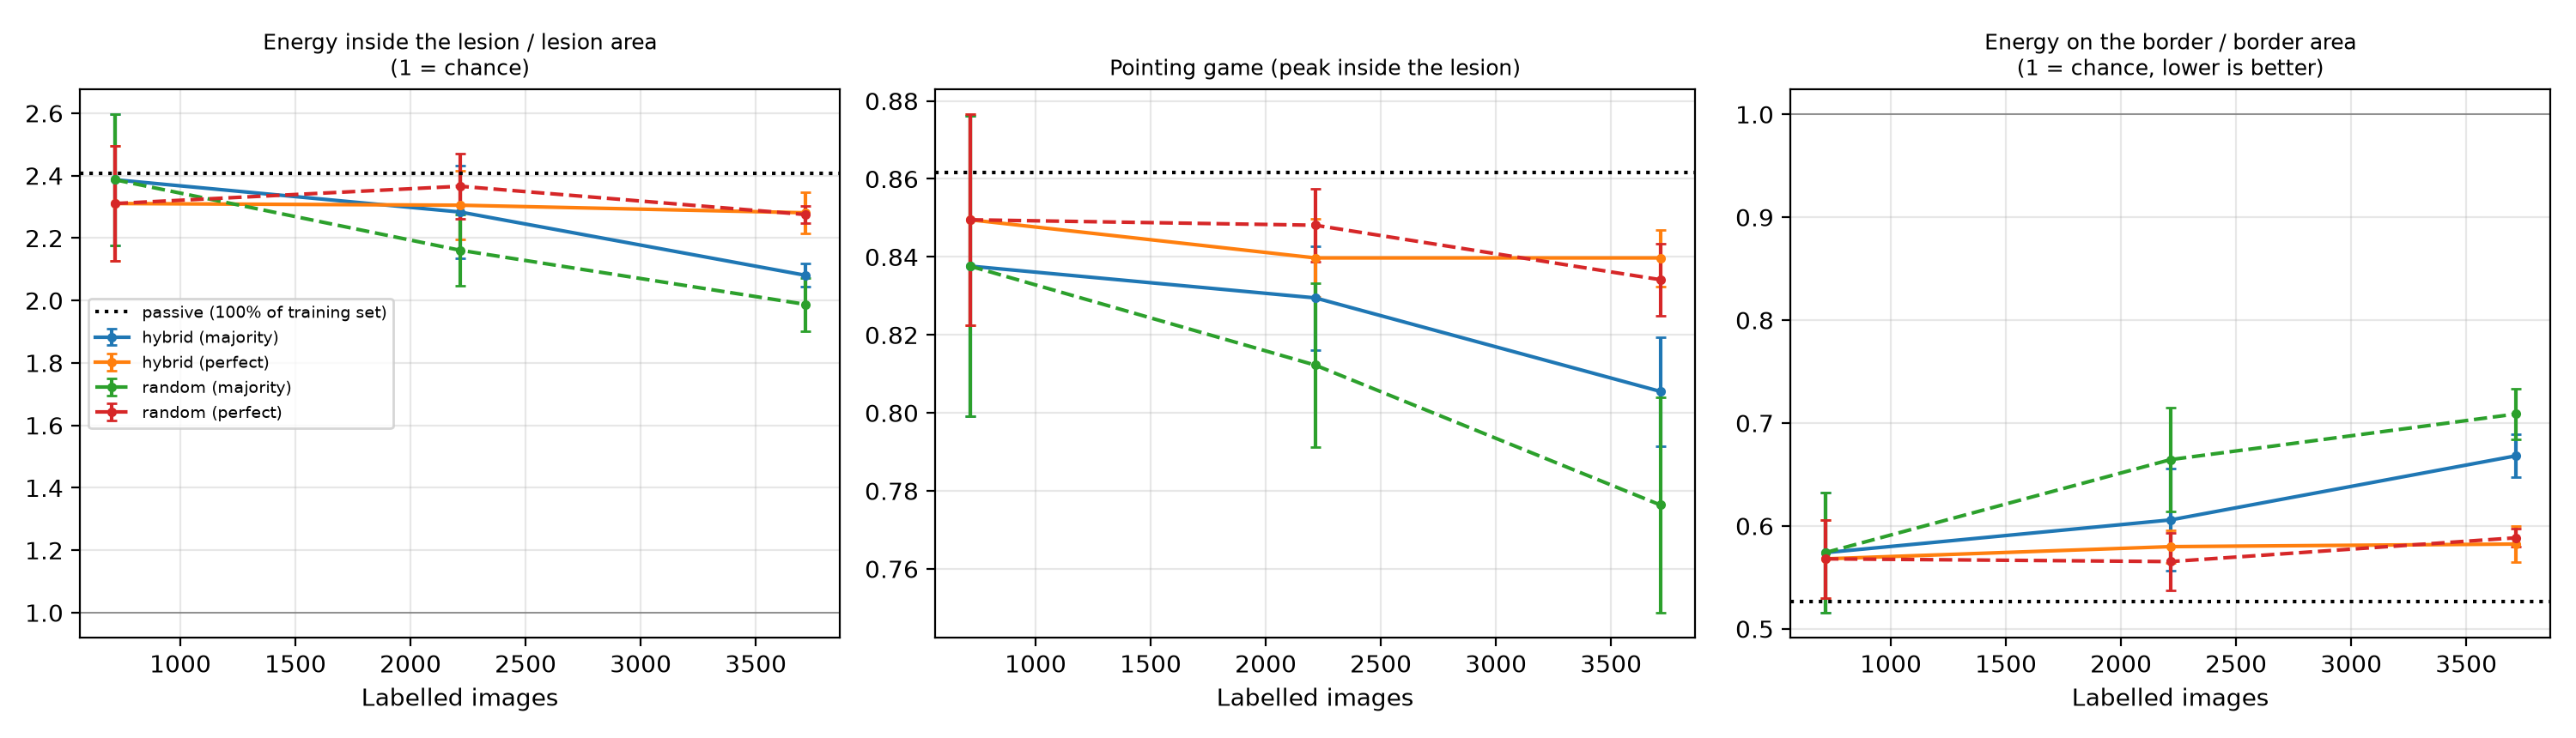

In [8]:
# Localisation metrics against the number of labelled images
display(IPImage(filename=str(FIGURES / "gradcam_vs_labels.png"), width=1000))

## 7. Localisation per class and per type of error

To understand when the heat maps are less reliable, the metrics are also grouped by the true class of the image and by the type of result of the prediction: correct, the two clinically important confusions between melanoma and nevus (`mel → nv`, a missed melanoma, and `nv → mel`, a false melanoma) and the other errors. This is done for the passive baseline and for the final active learning model used by the app (hybrid, perfect oracle, seed 0, last cycle).

In [9]:
def outcome(true, pred):
    # Type of result of one prediction (correct, the two mel <-> nv errors, or another error)
    t, p = CLASSES[true], CLASSES[pred]
    if t == p:
        return "correct"
    if (t, p) == ("nv", "mel"):
        return "nv -> mel (false melanoma)"
    if (t, p) == ("mel", "nv"):
        return "mel -> nv (missed melanoma)"
    return "other error"


# Check that the saved 'outcome' column follows this definition
print("Outcome column consistent:", (per_img.apply(lambda r: outcome(r.true, r.pred), axis=1) == per_img.outcome).all())

base = per_img[per_img.kind == "passive"]
al_all = per_img[per_img.kind == "AL"]
final_al = al_all[(al_all.strategy == "hybrid") & (al_all.oracle == "perfect") & (al_all.seed == 0)
                  & (al_all.n_labelled == al_all.n_labelled.max())]
rows = []
for model_name, sub in (("passive (100%)", base), ("active learning (hybrid, 50%)", final_al)):
    for gtype, col in (("class (true)", sub.true.map(lambda i: CLASSES[i])), ("outcome", sub.outcome)):
        t = sub.groupby(col)[METRICS].mean().round(4)
        t["n"] = sub.groupby(col).size()
        t.insert(0, "group_type", gtype)
        t.insert(0, "model", model_name)
        rows.append(t)
byg = pd.concat(rows)

saved_byg = pd.read_csv(TABLES / "gradcam_by_group.csv", index_col=0)
print("Same as the saved table:", np.allclose(byg.select_dtypes("number"), saved_byg.select_dtypes("number")))
byg

Outcome column consistent: True
Same as the saved table: True


,model,group_type,energy_in_mask,energy_ratio,pointing_game,iou,border_ratio,n
akiec,passive (100%),class (true),0.5233,1.3292,0.6739,0.1944,0.7230,46
bcc,passive (100%),class (true),0.4408,2.0365,0.7568,0.2635,0.5216,74
bkl,passive (100%),class (true),0.4081,1.5169,0.6752,0.2378,0.8451,157
df,passive (100%),class (true),0.4039,1.4803,0.7059,0.2140,0.7020,17
mel,passive (100%),class (true),0.5180,2.3362,0.8616,0.3901,0.5292,159
nv,passive (100%),class (true),0.4851,2.5994,0.9102,0.4623,0.4678,958
vasc,passive (100%),class (true),0.4823,5.3237,0.9500,0.5139,0.2060,20
correct,passive (100%),outcome,0.4844,2.4600,0.8964,0.4411,0.5079,1071
mel -> nv (missed melanoma),passive (100%),outcome,0.4447,3.5185,0.8966,0.4262,0.3731,29
nv -> mel (false melanoma),passive (100%),outcome,0.5675,3.0691,0.9573,0.4740,0.3628,117


The localisation depends on the class. Vascular lesions (`vasc`) and nevi (`nv`) are the best localised, while actinic keratoses (`akiec`), benign keratoses (`bkl`) and dermatofibromas (`df`) have an energy ratio close to 1.3–1.5 and the peak of the heat map falls outside the lesion in about one third of the images. For these classes, the heat map is a less reliable explanation of the prediction.

Errors are not always caused by looking at the wrong place. In the confusions between melanoma and nevus, the heat map is still well focused on the lesion (energy ratio above 2, pointing game around 0.9): the model looks at the lesion but misreads it, which is expected, since these two classes are also the ones most often confused by dermatologists. The **other errors** have the worst localisation (energy ratio about 1.6, pointing game about 0.6), so for these predictions a heat map outside the lesion is a useful warning sign for the clinician. The final active learning model behaves very similarly to the passive baseline.

## 8. Qualitative examples

The figure shows four test images (a correct melanoma, a correct nevus, a nevus predicted as melanoma and a missed melanoma), with the outline of the lesion mask in white. The columns are the passive baseline and the hybrid strategy with the fewest and with the most labelled images (seed 0), each with its predicted class.

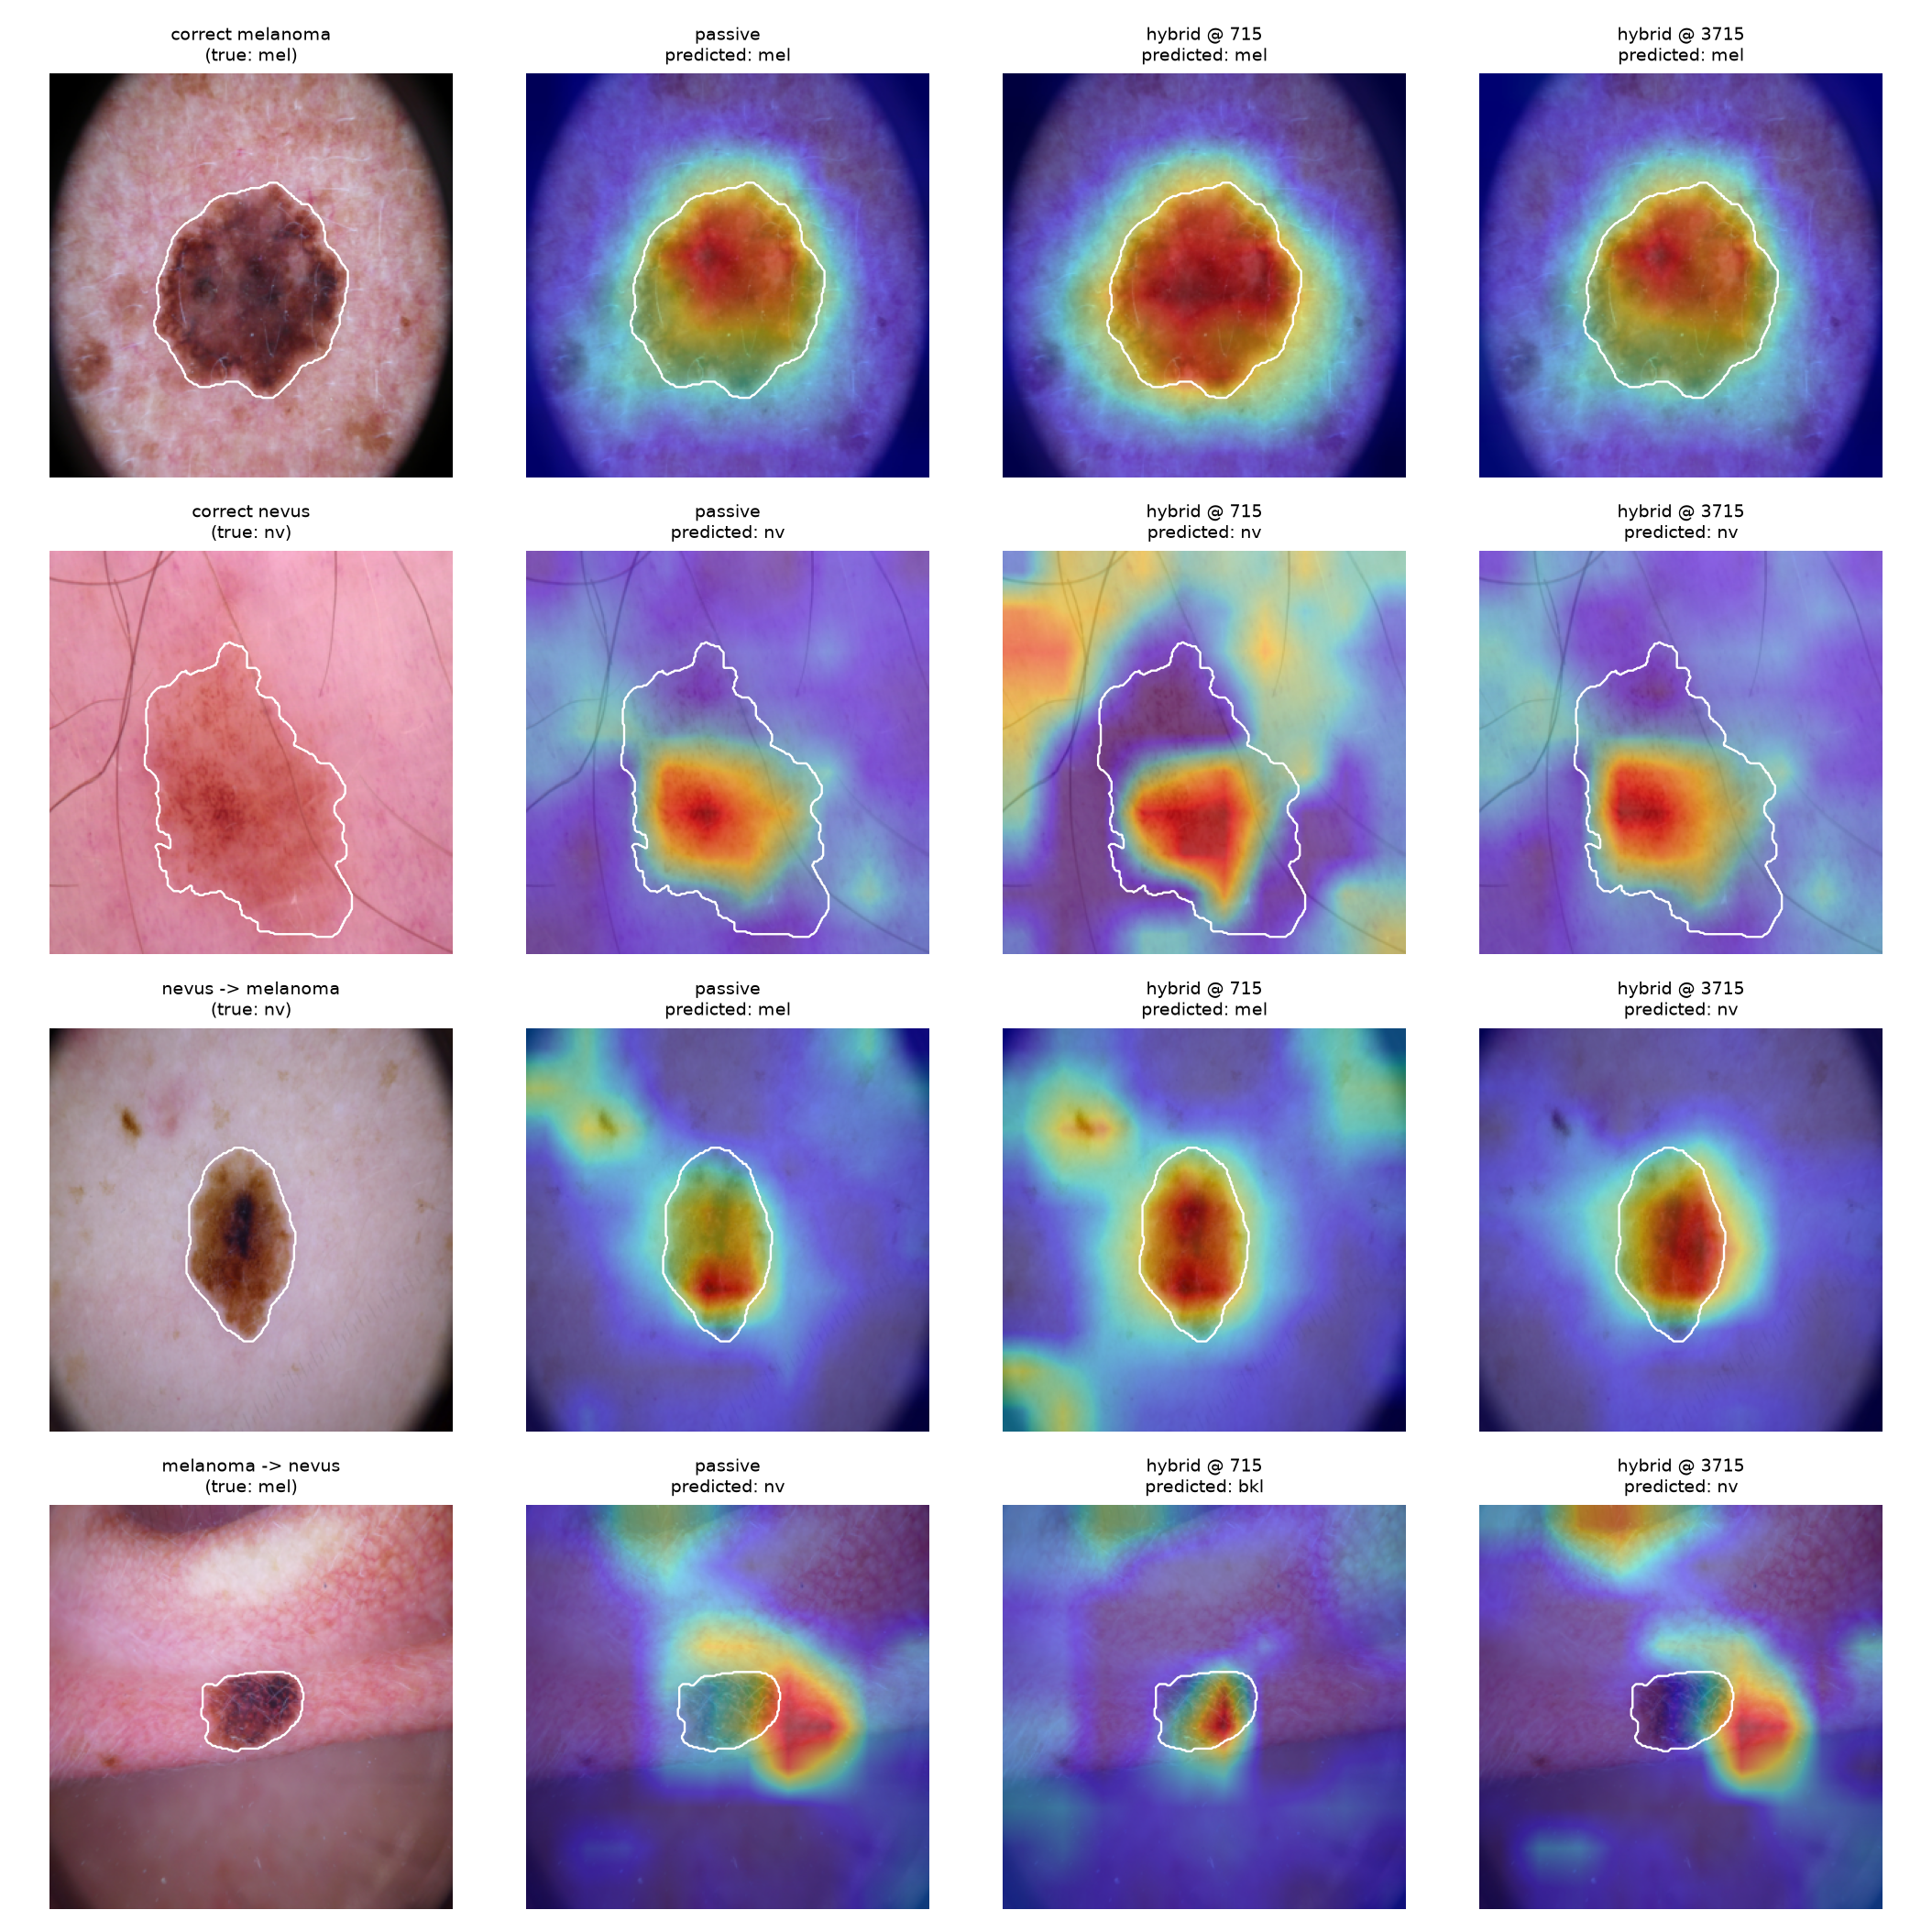

In [10]:
# Heat maps of the passive baseline and of the hybrid strategy at the smallest and largest budget
display(IPImage(filename=str(FIGURES / "gradcam_examples.png"), width=900))

## 9. Saved results

The results of the Grad-CAM evaluation are saved in the `results` folder:

- `tables/gradcam_per_image.csv`: the localisation metrics of every head on every test image, with the predicted class and the type of result.
- `tables/gradcam_summary.csv`: metrics per model and labelling budget (section 6).
- `tables/gradcam_by_group.csv`: metrics per class and per type of result, for the passive baseline and the final active learning model (section 7).
- `figures/gradcam_vs_labels.png` and `figures/gradcam_examples.png`: figures of sections 6 and 8.

The same closed-form Grad-CAM is used in the app of notebook `07_copilot_app.ipynb`, with the final active learning model. In the app, the heat map is computed for the class predicted with the 8 TTA views, while in this evaluation the class is the one predicted from the original view only, so the class can differ in borderline cases.